# Checkpoint 2 - Equity Research Agent Team

**FIN 67110 | LangGraph | Purdue GenAI Studio | Primary company: Visa**

A fixed graph runs seven filing-data tools, three analyst roles, a Strategy
Manager and an independent Verifier. Each analyst has one bounded revision slot.
The report preserves its source filings, calculation inputs, model handoffs,
original claims, verification marks and corrections.

The saved outputs contain actual provider responses. Run All executes the live
graph, including a new model call in the Verifier. Filing data and the dated
price replay the saved source snapshot so that the evidence periods stay fixed.
Every run saves a new evidence folder; previous runs remain available.

## Configuration

Install from the repository root:

```powershell
python -m pip install -r "Checkpoint 2/requirements.txt"
```

The selected model is `gpt-oss:120b` on Purdue GenAI Studio. Run All requires
`PURDUE_GENAI_API_KEY` in the private root `.env`; reading the saved notebook
outputs requires no credentials. Source legend: K = annual filing, Q = quarterly filing,
E = earnings release, and L = one-based line in the saved text.

In [1]:
from pathlib import Path
import sys
import json
import subprocess
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown
cwd=Path.cwd().resolve()
CHECKPOINT=next((p for p in (cwd,cwd/'Checkpoint 2') if (p/'submission_support.py').is_file()),None)
if CHECKPOINT is None:raise FileNotFoundError('Open from the repository root or Checkpoint 2 folder.')
sys.path.insert(0,str(CHECKPOINT))
from submission_support import load_manifest,run_selected_model,narrative_view,core_coverage
from team import read_json,core_groups
from verifier import extract_claims,citation,evaluate,digest,rounded
manifest=load_manifest()
PRIMARY=CHECKPOINT/manifest['primary_run']
BASELINE=CHECKPOINT/manifest['baseline_run']
REPEATED=CHECKPOINT/manifest['baseline_repeat_run']
pd.set_option('display.max_colwidth',100)
pd.set_option('display.max_columns',10)
print('Framework:',manifest['framework'])
print('Provider:',manifest['model_provider'],'| Model:',manifest['model'])
print('Execution: live model roles and mandatory live semantic verification')

Framework: LangGraph
Provider: Purdue GenAI Studio | Model: gpt-oss:120b
Execution: live model roles and mandatory live semantic verification


## Fixed graph and bounded revision

Code fixes node order, state boundaries, one revision per analyst and the final
Verifier. Research receives filing excerpts; Finance receives facts and computed
metrics; the Advisor receives only the two analyst outputs and their exposed
numbers. The Manager checks the five parts and three Insights. The Verifier
receives the compiled report and saved evidence, without analyst instructions.

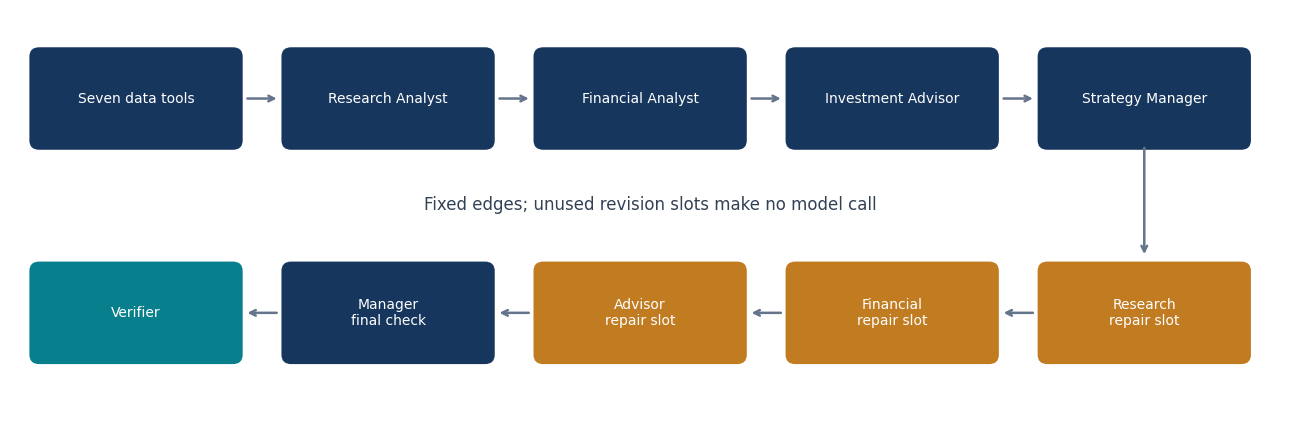

[Saved graph](runs/V_20261105T233534537538Z_8625fd/graph.mmd)

In [2]:
fig,ax=plt.subplots(figsize=(13,4.4))
ax.set(xlim=(-0.3,12.8),ylim=(0,4.4));ax.axis('off')
labels=['Seven data tools','Research Analyst','Financial Analyst','Investment Advisor','Strategy Manager',
        'Research repair slot','Financial repair slot','Advisor repair slot','Manager final check','Verifier']
positions=[(0,3),(2.6,3),(5.2,3),(7.8,3),(10.4,3),(10.4,0.7),(7.8,0.7),(5.2,0.7),(2.6,0.7),(0,0.7)]
for i,(label,(x,y)) in enumerate(zip(labels,positions)):
    color='#087f8c' if i==9 else '#c17c21' if 5<=i<=7 else '#17365d'
    ax.add_patch(FancyBboxPatch((x,y),2,0.9,boxstyle='round,pad=0.1',facecolor=color,edgecolor='none'))
    ax.text(x+1,y+0.45,label.replace(' repair ','\nrepair ').replace(' final ','\nfinal '),ha='center',va='center',color='white',fontsize=10)
    if i:
        px,py=positions[i-1]
        start,end=((px+1,py-0.05),(x+1,y+1.05)) if i==5 else (((px+2.12,py+0.45),(x-0.12,y+0.45)) if i<5 else ((px-0.12,py+0.45),(x+2.12,y+0.45)))
        ax.annotate('',xy=end,xytext=start,arrowprops=dict(arrowstyle='->',color='#64748b',lw=1.8))
ax.text(6.3,2.25,'Fixed edges; unused revision slots make no model call',ha='center',fontsize=12,color='#334155')
fig.tight_layout();plt.show()
display(Markdown('[Saved graph]('+manifest['primary_run']+'/graph.mmd)'))

## Primary company run

The tools resolve the ticker, select and identify filings, save line-addressable
text, extract same-period annual facts, calculate ratios, read the correct
quarterly columns and calculate peers on the same margin definition. A dated
market receipt records the price observation separately from the filings.

In [3]:
result=run_selected_model(PRIMARY)
RUN=Path(result['run_dir'])
catalog=read_json(RUN/'catalog.json')
report=(RUN/'report.md').read_text(encoding='utf-8')
verification=read_json(RUN/'verification.json')
claims=extract_claims(report)
manifest['primary_run']=RUN.relative_to(CHECKPOINT).as_posix()
from verifier import write_json
write_json(CHECKPOINT/'submission_manifest.json',manifest)
write_json(CHECKPOINT/'latest_run.json',{'run_dir':manifest['primary_run']})
from submission_index import write_submission_index
write_submission_index(CHECKPOINT)
display(pd.DataFrame([{'Ticker':manifest['primary_ticker'],'Execution':result['summary']['mode'],
    'Manager approved':result['manager_approved'],'Verifier ran':result['summary']['verifier_ran'],
    'Numerical claims':verification['claim_count'],'Original findings':verification['errors'],
    'Unresolved':verification.get('unresolved_errors',0),'Semantic check':verification['semantic_status']}]))
display(pd.DataFrame({'Node':result['trace']}))
display(Markdown('[Selected live report]('+manifest['primary_run']+'/verified_report_readable.md) | '
                 '[Original report]('+manifest['primary_run']+'/report.md) | '
                 '[Provider call metadata]('+manifest['primary_run']+'/call_counts.json)'))

Tools: seven deterministic filing steps
1. Resolve ticker to CIK
2. Select filings and verify index Accepted times
3. Download 10-K, 10-Q, and Exhibit 99.1 as text
4. Extract annual facts, tags, periods, and sources
5. Calculate ratios in Python
6. Read quarterly revenue and GAAP EPS source lines
7. Read peers' own 10-Ks on the same GAAP margin definition
Research Analyst
Financial Analyst
Investment Advisor
Strategy Manager
Research Analyst revision slot
Financial Analyst revision slot
Investment Advisor revision slot
Strategy Manager final check
Verifier


,Ticker,Execution,Manager approved,Verifier ran,Numerical claims,Original findings,Unresolved,Semantic check
0,V,live,True,True,41,0,0,completed


,Node
0,Tools: seven deterministic filing steps
1,Research Analyst
2,Financial Analyst
3,Investment Advisor
4,Strategy Manager
5,Research Analyst revision slot
6,Financial Analyst revision slot
7,Investment Advisor revision slot
8,Strategy Manager final check
9,Verifier


[Selected live report](runs/V_20261105T234050665521Z_342a19/verified_report_readable.md) | [Original report](runs/V_20261105T234050665521Z_342a19/report.md) | [Provider call metadata](runs/V_20261105T234050665521Z_342a19/call_counts.json)

## Core financial claims

Ratios use code-calculated inputs and explicit definitions. Annual and quarterly
periods remain separate. The annual-filing P/E uses the recorded close divided
by the selected annual GAAP diluted EPS; it is labelled separately from a current
TTM valuation. Peer fiscal periods and business mixes can differ.

Each source key resolves to exact filing lines, tags, periods and accessions in the run's `catalog.json`. The linked full report prints those citations beside each figure.

In [4]:
coverage=pd.DataFrame(core_coverage(manifest['primary_ticker'],report,catalog,RUN))
assert len(coverage)==11 and coverage['Covered'].all()
display(coverage)
peer_rows=[]
for ticker in read_json(RUN/'configuration.json')['peers']+[manifest['primary_ticker']]:
    rev=catalog[ticker+'.fact.revenue'];op=catalog[ticker+'.fact.operating_income'];margin=catalog[ticker+'.ratio.operating_margin']
    peer_rows.append({'Ticker':ticker,'Fiscal end':rev['end'],'Reported revenue (USD)':rev['value'],
                     'GAAP operating income (USD)':op['value'],'GAAP operating margin (%)':margin['value'],
                     'Revenue label':rev['source_text'].split('|')[0]})
display(pd.DataFrame(peer_rows))

,Core claim,Covered,Value,Period,Source keys
0,1 Total annual revenue,True,"40,000,000,000.00 USD",2024-10-01 to 2025-09-30,V.fact.revenue
1,2 Annual revenue growth,True,11.34 %,2024-10-01 to 2025-09-30,V.ratio.revenue_growth
2,3 Operating income and margin,True,"23,994,000,000.00 USD; 59.99 %",2024-10-01 to 2025-09-30,V.fact.operating_income; V.ratio.operating_margin
3,4 Net income attributable to company,True,"20,058,000,000.00 USD",2024-10-01 to 2025-09-30,V.fact.net_income
4,5 Annual GAAP diluted EPS,True,10.20 USD/shares,2024-10-01 to 2025-09-30,V.fact.diluted_eps
5,6 Return on average equity,True,52.07 %,2024-10-01 to 2025-09-30,V.ratio.return_on_average_equity
6,7 Debt/equity including current portion,True,0.66 x,2024-10-01 to 2025-09-30,V.ratio.debt_to_equity
7,8 Free cash flow,True,"21,577,000,000.00 USD",2024-10-01 to 2025-09-30,V.ratio.free_cash_flow
8,9 Latest quarter revenue,True,"12,139,000,000.00 USD",three months ended 2026-09-30,V.quarter.quarter_net_revenue
9,10 Latest quarter nominal growth,True,13.19 %,2026-09-30,V.quarter.revenue_growth


,Ticker,Fiscal end,Reported revenue (USD),GAAP operating income (USD),GAAP operating margin (%),Revenue label
0,MA,2025-12-31,32791000000,18897000000,57.628618,Net Revenue
1,PYPL,2025-12-31,33172000000,6065000000,18.283492,Net revenues
2,V,2025-09-30,40000000000,23994000000,59.985000,Net revenue


## Five-part research report

In [5]:
display(Markdown(narrative_view(report,catalog,RUN)))
insights=[c for c in claims if c['text'].startswith('Insight:')]
assert len(insights)==3
for claim in insights:
    display(Markdown('**'+claim['text']+'** '+f"{rounded(claim['value']):,.2f} {claim['unit']}"))
    display(Markdown('Source: '+citation(catalog[claim['source']],catalog).replace('|',' / ')))

## Overview

Visa is a global payments technology company that operates a four‑party network linking consumers, issuers, acquirers and merchants, with the purpose of uplifting everyone by being the best way to pay and be paid [source:K:L151][source:Q:L1253]. The firm does not issue cards, extend credit or set rates for cardholders. Revenue growth is driven by higher payments volume, cross‑border activity and processed transactions, which together lifted net revenue in the most recent quarter [source:K:L839][source:E:L39]. Offsetting this growth are higher client incentives, a recurring theme noted in the filing [source:K:L839][source:E:L44]. The company maintains a strong operating margin **59.99 %** [source: V.ratio.operating_margin] and generates robust operating cash flow **21,577,000,000.00 USD** [source: V.ratio.free_cash_flow].

## Market Positioning and Growth Outlook

The payments industry is undergoing rapid change, with existing and emerging competitors challenging Visa’s network through new technologies, ecommerce, mobile payments, blockchain and digital currencies [source:K:L382]. Visa’s strategy focuses on accelerating revenue growth through consumer payments, commercial and money‑movement solutions, and value‑added services [source:K:L214]. In consumer payments, Visa is investing in token technology, cross‑border capabilities and offerings for affluent consumers to expand transaction volume [source:K:L220]. The firm cites continued resilience in consumer spending and expansion in digital commerce as key drivers of volume growth [source:Q:L1402]. These initiatives position Visa to capture additional share of evolving payment flows while leveraging its extensive network.

## Valuation Insights

Visa posts a high operating margin of **59.99 %** [source: V.ratio.operating_margin] and a strong return on average equity of **52.07 %** [source: V.ratio.return_on_average_equity]. Debt‑to‑equity stands at **0.66 x** [source: V.ratio.debt_to_equity], indicating moderate leverage. Free cash flow of **21,577,000,000.00 USD** [source: V.ratio.free_cash_flow] underpins share repurchases and dividend growth. The annual price‑earnings multiple of **39.40 x** [source: V.ratio.price_earnings] reflects market expectations relative to earnings. Revenue grew by **11.34 %** [source: V.ratio.revenue_growth] year over year, supporting the top‑line momentum.

## Future Developments and Strategic Recommendations

Visa announced a definitive agreement to acquire BioCatch, a behavioral‑first fraud‑intelligence provider, to strengthen its security and analytics capabilities [source:E:L68]. Ongoing regulatory scrutiny, such as the UK interchange litigation, represents a material risk and may affect pricing and volume dynamics [source:Q:L1180]. The company must continue to manage client incentives and litigation reserves, as highlighted in its discussion of legal and regulatory proceedings [source:Q:L555][source:Q:L1109]. Expanding the Visa Acceptance Platform and token management services can deepen partnerships and create new revenue streams [source:K:L309]. Monitoring changes to interchange fee regulations is critical, given their impact on transaction volume and net revenue [source:K:L485].

## Investment Recommendation

<!-- thesis-start -->
Buy. Visa’s business durability is supported by a high operating margin **59.99 %** [source: V.ratio.operating_margin], strong free cash flow **21,577,000,000.00 USD** [source: V.ratio.free_cash_flow], and moderate leverage **0.66 x** [source: V.ratio.debt_to_equity]. The firm faces risk from rising client incentives [source:K:L839][source:E:L44] and ongoing regulatory scrutiny such as the UK interchange litigation [source:Q:L1180]. If operating margin were to decline materially or regulatory outcomes were to tighten pricing, the recommendation would be revised downward.
<!-- thesis-end -->

**Insight: Leverage remains moderate, as indicated by the debt‑to‑equity ratio.** 0.66 x

Source: (19,602,000,000 + 5,569,000,000) / 37,909,000,000; V/10-K.txt L1516; us-gaap:LongTermDebtNoncurrent; 2025-09-30; 0001403161-25-000089; Long-term debt  /  19,602  /   /   /  20,836  / ; V/10-K.txt L1513; us-gaap:LongTermDebtCurrent; 2025-09-30; 0001403161-25-000089; Current maturities of debt  /  5,569  /   /   /  —  / ; V/10-K.txt L1539; us-gaap:StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest; 2025-09-30; 0001403161-25-000089; Total equity  /  37,909  /   /   /  39,137  / 

**Insight: Visa generates a strong return on equity** 52.07 %

Source: 20,058,000,000 / ((39,137,000,000 + 37,909,000,000) / 2) * 100; V/10-K.txt L2877; us-gaap:NetIncomeLoss; 2024-10-01 to 2025-09-30; 0001403161-25-000089; Net income  /  $  /  20,058  /   /   /   /   /   /   /   /   /   /   / ; V/10-K.txt L1539; us-gaap:StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest; 2024-09-30; 0001403161-25-000089; Total equity  /  37,909  /   /   /  39,137  / ; V/10-K.txt L1539; us-gaap:StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest; 2025-09-30; 0001403161-25-000089; Total equity  /  37,909  /   /   /  39,137  / 

**Insight: Visa delivers an exceptionally high return on equity** 52.07 %

Source: 20,058,000,000 / ((39,137,000,000 + 37,909,000,000) / 2) * 100; V/10-K.txt L2877; us-gaap:NetIncomeLoss; 2024-10-01 to 2025-09-30; 0001403161-25-000089; Net income  /  $  /  20,058  /   /   /   /   /   /   /   /   /   /   / ; V/10-K.txt L1539; us-gaap:StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest; 2024-09-30; 0001403161-25-000089; Total equity  /  37,909  /   /   /  39,137  / ; V/10-K.txt L1539; us-gaap:StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest; 2025-09-30; 0001403161-25-000089; Total equity  /  37,909  /   /   /  39,137  / 

## Independent verification marks

Code checks saved facts and their XBRL contexts, source lines, fiscal-quarter
columns, units, price receipts and ratio arithmetic. The separate model check
examines whether the evidence supports each claim's period and definition.
Original marks and corrections remain saved. The Advisor's subjective thesis is
excluded; its deciding metric and separate Insight are checked.

In [6]:
marks=pd.DataFrame(verification['marks'])
display(marks[['id','mark','reported','corrected','reason','semantic_status']])
assert verification['semantic_status']=='completed'
assert verification.get('unresolved_errors',0)==0
print('Verified source observations:',len(catalog))
print('Original marks:',marks['mark'].value_counts().to_dict())

,id,mark,reported,corrected,reason,semantic_status
0,C001,correct,5.998500e+01,None,Exact source context and rounded value match.,completed
1,C002,correct,2.157700e+10,None,Exact source context and rounded value match.,completed
2,C003,correct,5.998500e+01,None,Exact source context and rounded value match.,completed
3,C004,correct,5.206760e+01,None,Exact source context and rounded value match.,completed
4,C005,correct,6.639848e-01,None,Exact source context and rounded value match.,completed
5,C006,correct,2.157700e+10,None,Exact source context and rounded value match.,completed
6,C007,correct,3.939804e+01,None,Exact source context and rounded value match.,completed
7,C008,correct,1.133998e+01,None,Exact source context and rounded value match.,completed
8,C009,correct,4.000000e+10,None,Exact source context and rounded value match.,completed
9,C010,correct,2.399400e+10,None,Exact source context and rounded value match.,completed


Verified source observations: 53
Original marks: {'correct': 41}


## Costco baseline and repeated-run evidence

The baseline uses its own annual filing and the release's 16-week quarter.
Quarterly total revenue includes membership fees; net sales and the full-year
columns are not substituted. Both selected baseline runs made actual provider
calls and saved separate evidence folders.

In [7]:
baseline_summary=read_json(BASELINE/'summary.json');repeat_summary=read_json(REPEATED/'summary.json')
baseline_verification=read_json(BASELINE/'verification.json')
baseline_report=(BASELINE/'report.md').read_text(encoding='utf-8')
baseline_catalog=read_json(BASELINE/'catalog.json')
assert baseline_summary['mode']==repeat_summary['mode']=='live'
assert baseline_summary['manager_approved'] and repeat_summary['manager_approved']
assert read_json(BASELINE/'node_order.json')==read_json(REPEATED/'node_order.json')
assert BASELINE!=REPEATED
for folder in (BASELINE,REPEATED):assert all(n<=2 for n in read_json(folder/'call_counts.json').values())
display(pd.DataFrame([{'Run':p.name,**read_json(p/'call_counts.json')} for p in (BASELINE,REPEATED)]))
display(pd.DataFrame(core_coverage('COST',baseline_report,baseline_catalog,BASELINE)))
quarter=read_json(BASELINE/'quarter_observations.json')
print('Quarter duration:',quarter['quarter_duration'],'| End:',quarter['period_end'],'| Release:',quarter['release_date'])
display(Markdown('[Baseline report]('+manifest['baseline_run']+'/verified_report_readable.md) | '
                 '[Second baseline report]('+manifest['baseline_repeat_run']+'/verified_report_readable.md)'))

,Run,Research Analyst,Financial Analyst,Investment Advisor,Strategy Manager,Verifier
0,COST_20261105T231700361085Z_ec30bc,2,1,2,2,1
1,COST_20261105T231903165410Z_096a9f,2,1,2,2,1


,Core claim,Covered,Value,Period,Source keys
0,1 Total annual revenue,True,"303,154,000,000.00 USD",2025-09-01 to 2026-08-30,COST.fact.revenue
1,2 Annual revenue growth,True,10.14 %,2025-09-01 to 2026-08-30,COST.ratio.revenue_growth
2,3 Operating income and margin,True,"11,685,000,000.00 USD; 3.85 %",2025-09-01 to 2026-08-30,COST.fact.operating_income; COST.ratio.operating_margin
3,4 Net income attributable to company,True,"9,226,000,000.00 USD",2025-09-01 to 2026-08-30,COST.fact.net_income
4,5 Annual GAAP diluted EPS,True,20.76 USD/shares,2025-09-01 to 2026-08-30,COST.fact.diluted_eps
5,6 Return on average equity,True,28.40 %,2025-09-01 to 2026-08-30,COST.ratio.return_on_average_equity
6,7 Debt/equity including current portion,True,0.17 x,2025-09-01 to 2026-08-30,COST.ratio.debt_to_equity
7,8 Free cash flow,True,"9,382,000,000.00 USD",2025-09-01 to 2026-08-30,COST.ratio.free_cash_flow
8,9 Latest quarter revenue,True,"95,723,000,000.00 USD",16 weeks ended 2026-08-30,COST.quarter.quarter_net_revenue
9,10 Latest quarter nominal growth,True,11.10 %,2026-08-30,COST.quarter.revenue_growth


Quarter duration: 16 weeks | End: 2026-08-30 | Release: 2026-09-24


[Baseline report](runs/COST_20261105T231700361085Z_ec30bc/verified_report_readable.md) | [Second baseline report](runs/COST_20261105T231903165410Z_096a9f/verified_report_readable.md)

## Seeded errors, invented growth and clean report

Each planted report is a separate copy. The saved filing evidence is unchanged.
Verify-only runs the Verifier without rerunning the analysts. The EPS test also
alters the report's quoted source line; the genuine filing remains unchanged.

In [8]:
original_hash=digest(BASELINE/'report.md')
test_rows=[]
for name,record in manifest['seeded_tests'].items():
    checked=read_json(CHECKPOINT/record['verified_run']/'verification.json')
    assert read_json(CHECKPOINT/record['verified_run']/'node_order.json')==['Verifier']
    assert checked['semantic_status']=='completed'
    mark=next(m for m in checked['marks'] if m['id']==record['claim_id'])
    assert mark['mark'] in {'wrong','unsupported'} and mark['corrected'] is not None
    test_rows.append({'Test':name,'Reported':mark['reported'],'Mark':mark['mark'],'Correction':mark['corrected'],
                      'Semantic check':checked['semantic_status']})
    display(Markdown(name+': [planted report]('+record['seeded_run']+'/report.md) | '
                     '[saved live verifier marks]('+record['verified_run']+'/verified_report_readable.md)'))
clean=read_json(CHECKPOINT/manifest['clean_verification_run']/'verification.json')
assert clean['errors']==0 and digest(BASELINE/'report.md')==original_hash
assert clean['semantic_status']=='completed'
display(pd.DataFrame(test_rows))
print('Clean report:',clean['claim_count'],'numerical claims; no verification findings.')

eps_plus_one: [planted report](runs/COST_20261105T232111498131Z_7d807f_eps_plus_one/report.md) | [saved live verifier marks](runs/COST_20261105T232111512941Z_540bc4_verify_only/verified_report_readable.md)

growth_plus_four: [planted report](runs/COST_20261105T232203334402Z_3c1381_growth_plus_four/report.md) | [saved live verifier marks](runs/COST_20261105T232203351372Z_b63b6a_verify_only/verified_report_readable.md)

wrong_quarter: [planted report](runs/COST_20261105T232247531759Z_7bc07b_wrong_quarter/report.md) | [saved live verifier marks](runs/COST_20261105T232247545988Z_580401_verify_only/verified_report_readable.md)

ambiguous_roe: [planted report](runs/COST_20261105T232327063931Z_cfb63a_ambiguous_roe/report.md) | [saved live verifier marks](runs/COST_20261105T232327080872Z_12b533_verify_only/verified_report_readable.md)

,Test,Reported,Mark,Correction,Semantic check
0,eps_plus_one,21.760000,wrong,20.760000,completed
1,growth_plus_four,14.143695,wrong,10.143695,completed
2,wrong_quarter,20.760000,wrong,6.750000,completed
3,ambiguous_roe,28.402112,unsupported,28.402112,completed


Clean report: 43 numerical claims; no verification findings.


## General company interface

The same graph accepts another ticker, optional peers and a dated price. The
local page displays node progress and the verified report. The selected partner
run, when recorded in the manifest, uses the same interface and graph.

```powershell
python -m streamlit run "Checkpoint 2/app.py"
```

```powershell
python "Checkpoint 2/team.py" COST --peers WMT,TGT,BJ --as-of 2026-11-05 --market-provider wrds --price-date 2026-09-24 --model-provider purdue
```

Verify a saved run with `python "Checkpoint 2/team.py" --verify-only "Checkpoint 2/runs/RUN_FOLDER"`.
There is no verifier-skip option.

In [9]:
if manifest.get('partner_run'):
    partner=CHECKPOINT/manifest['partner_run']
    display(pd.DataFrame([read_json(partner/'summary.json')]))
    display(Markdown('[Partner-company verified report]('+manifest['partner_run']+'/verified_report_readable.md)'))
else:
    print('Partner-selected run: not yet recorded in the submission manifest.')
checks=subprocess.run([sys.executable,'-m','unittest','discover','-s',str(CHECKPOINT/'tests'),'-v'],
                      cwd=CHECKPOINT.parent,capture_output=True,text=True)
if checks.returncode:print(checks.stdout+checks.stderr)
assert checks.returncode==0
print('Regression suite:',checks.stderr.strip().splitlines()[-3:])

,run_dir,mode,manager_approved,errors,verifier_ran,...,replayed_response_counts,fixture_response_counts,human_audit,student_personas,partner_pick
0,runs/V_20261105T234553142062Z_c902dc,live,True,0,True,...,{},{},pending,pending,pending


[Partner-company verified report](runs/V_20261105T234553142062Z_c902dc/verified_report_readable.md)

Regression suite: ['Ran 27 tests in 49.436s', '', 'OK']


## References

[Lab 4](../Instructions/Lab%204.pdf), [Lab 5](../Instructions/Lab%205.pdf),
[Week 3](../Instructions/Week%203.pdf), and [Report Audit](../Instructions/Report%20Audit.pdf).

[LangGraph Graph API](https://docs.langchain.com/oss/python/langgraph/graph-api),
[Purdue GenAI Studio API](https://docs.rcac.purdue.edu/services/genai/api/),
[official OpenAI structured outputs](https://developers.openai.com/api/docs/guides/structured-outputs?api-mode=responses).